Max difference vs Gaussian: 1


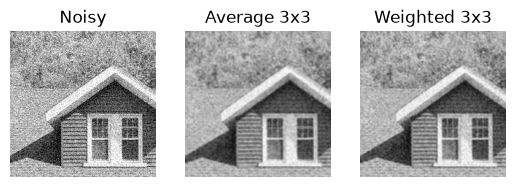

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("../../images/house.png", 0)
noisy = np.clip(img + np.random.normal(0, 25, img.shape), 0, 255).astype(np.uint8)

k = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
weighted = cv2.filter2D(noisy, -1, k)
ref = cv2.GaussianBlur(noisy, (3, 3), 0)      # OpenCV's built-in version
print("Max difference vs Gaussian:", np.abs(weighted.astype(int) - ref).max())

average = cv2.blur(noisy, (3, 3))
crop = lambda x: x[100:300, 100:300]
for i, (im, t) in enumerate([(noisy, "Noisy"), (average, "Average 3x3"), (weighted, "Weighted 3x3")]):
    plt.subplot(1, 3, i + 1); plt.imshow(crop(im), cmap="gray", vmin=0, vmax=255); plt.title(t); plt.axis("off")
plt.show()